In [220]:
import numpy as np
import matplotlib.pyplot as plt
import math
np.random.seed(67)

# Questão 1. Box-Muller

In [221]:
def Normal_BoxMuller():
    u1 = np.random.uniform()
    u2 = np.random.uniform()

    u_2pi = 2*np.pi*u2
    t = -np.log(u1)

    z1 = np.sqrt(2*t)*np.cos(u_2pi)
    z2 = np.sqrt(2*t)*np.sin(u_2pi)

    return z1,z2

In [222]:
#Densidade da Normal Padrão
def normal(x):
    num = np.exp(-(x**2)/2)
    den = np.sqrt(2*np.pi)
    return num/den

In [223]:
N = 10**4 #Valor usado nos labs 

Normal_z1 = []
Normal_z2 = []

for i in range(N):
    z1,z2 = Normal_BoxMuller()
    Normal_z1.append(z1)
    Normal_z2.append(z2)

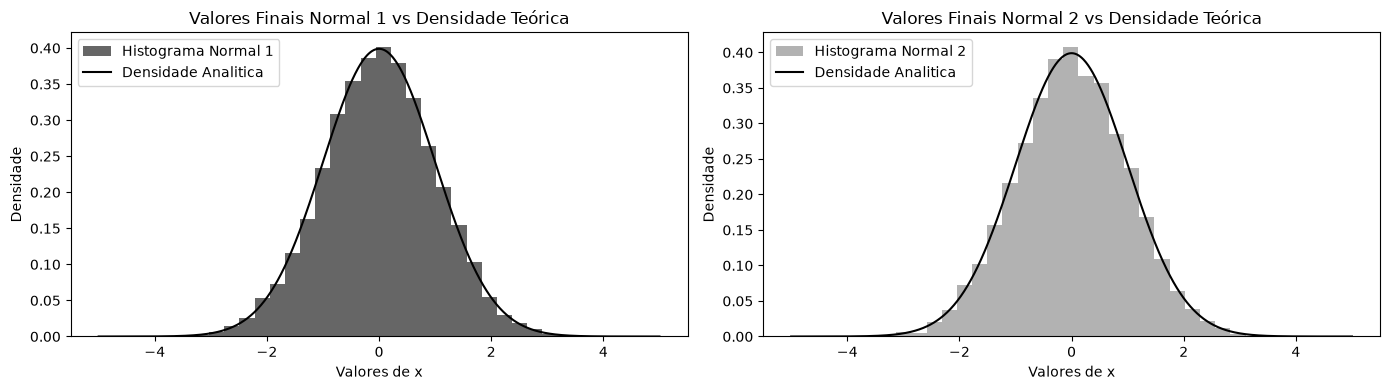

In [224]:
plt.figure(figsize=(14,4))

eixo_x = np.linspace(-5,5,1000)

plt.subplot(1,2,1)
plt.hist(Normal_z1,bins=30, density=True, alpha=0.6, color='black', label='Histograma Normal 1')
plt.plot(eixo_x, normal(eixo_x),label='Densidade Analitica', color ='black')

plt.xlabel('Valores de x')
plt.ylabel('Densidade')
plt.title(f'Valores Finais Normal 1 vs Densidade Teórica')
plt.legend(loc = 'upper left')

plt.subplot(1,2,2)
plt.hist(Normal_z2, bins=30, density=True, alpha=0.6, color='grey', label='Histograma Normal 2')
plt.plot(eixo_x, normal(eixo_x),label='Densidade Analitica', color = 'black')

plt.xlabel('Valores de x')
plt.ylabel('Densidade')
plt.title(f'Valores Finais Normal 2 vs Densidade Teórica')
plt.legend(loc = 'upper left')

plt.tight_layout()
plt.show()

In [225]:
#Cálculo das médias e variâncias amostrais

media_z1 = np.mean(Normal_z1)
media_z2 = np.mean(Normal_z2)

var_z1 = np.var(Normal_z1)
var_z2 = np.var(Normal_z2)

print(media_z1,media_z2)
print(var_z1,var_z2)

0.010829025268228107 0.0029750043222283966
1.0123414585343176 0.9871845222121559


# Questão 2. Normal Bivariada

In [226]:
mi_x = 0
dp_x = 1
p_cor = 0.6
mi_y = 0
dp_y = np.sqrt(4)
n = 10000
amostra_Y = []
amostra_X = []
amostra_XY = []
for i in range(n):
    z1, z2 = Normal_BoxMuller()
    X = mi_x + dp_x * z1
    Y = mi_y + dp_y * (p_cor * z1 + np.sqrt(1 - p_cor**2) * z2)
    amostra_Y.append(Y)
    amostra_X.append(X)
    amostra_XY.append([X,Y])
    

media_amostral_X = np.mean(amostra_X)
correlacao_amostral = np.corrcoef(amostra_X, amostra_Y)[0,1]
variancia_amostral_X = np.var(amostra_X)
variancia_amostral_Y = np.var(amostra_Y)
media_amostral_Y = np.mean(amostra_Y)
print(f"A variancia amostral de X é: {variancia_amostral_X:.3f}")
print(f"A média amostral de X é: {media_amostral_X:.3f}")
print(f"A variancia amostral de Y é: {variancia_amostral_Y:.3f}")
print(f"A média amostral de Y é: {media_amostral_Y:.3f}")


print(f"A correlação amostral é: {correlacao_amostral:.3f}")

A variancia amostral de X é: 1.008
A média amostral de X é: 0.004
A variancia amostral de Y é: 4.006
A média amostral de Y é: 0.011
A correlação amostral é: 0.601


A matriz de covariancia é representador por: 
[[1.00835498 1.2079205 ]
 [1.2079205  4.00613879]]


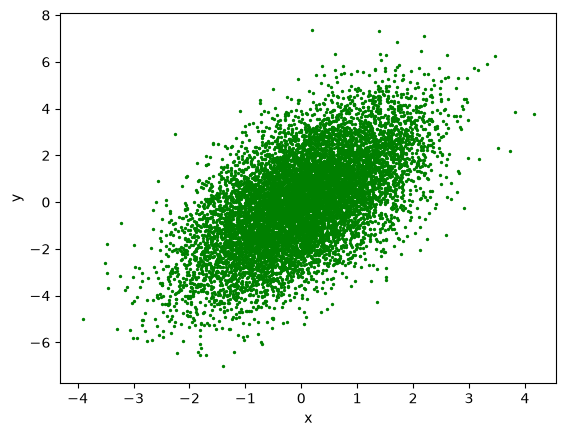

In [227]:
#Criando o gráfico de dispersão e a matri
plt.scatter(amostra_X, amostra_Y, color='green', s=2)
plt.ylabel('y')
plt.xlabel('x')
print(f"A matriz de covariancia é representador por: \n{np.cov(amostra_X, amostra_Y)}")

# Questão 3. Qui-Quadrado

In [228]:
# Normal Box-Muller para amostras de tamanho M
def normal(mi,sigma2, M):
  amostra = []
  for i in range(M):
    u1 = np.random.uniform()
    u2 = np.random.uniform()

    u_2pi = 2*np.pi*u2
    t = -np.log(u1)
    x = np.sqrt(2*t)*np.cos(u_2pi)

    amostra.append(np.sqrt(sigma2)*x + mi)
  
  return amostra

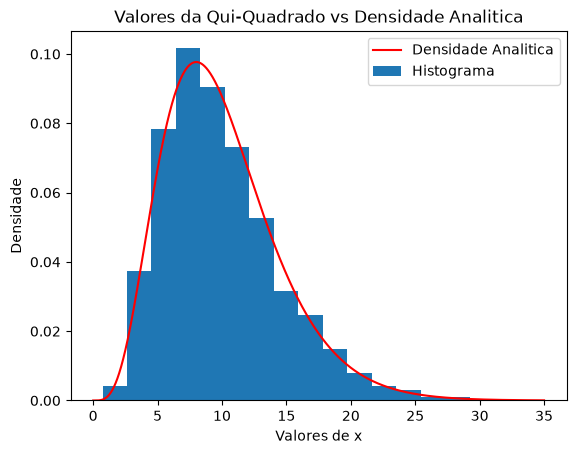

In [238]:
dados = []
for v in range(10):
  z = normal(0,1,1000)
  dados.append(np.array(z)**2)

qui = np.sum(dados, axis = 0)

def f_qui(x, v):
  return (x**((v/2) - 1) * np.exp(-x/2))/(2**(v/2) * math.gamma(v/2))

eixo_x = np.linspace(0, 35, 10_000)

plt.title("Valores da Qui-Quadrado vs Densidade Analitica")
plt.xlabel('Valores de x')
plt.ylabel('Densidade')

plt.plot(np.linspace(0, 35, 10_000), f_qui(eixo_x, 10), color="red", label="Densidade Analitica")
plt.hist(qui, density=True, bins=15, label="Histograma")

plt.legend()
plt.show()

In [230]:
print(f"Valor obtido: {np.mean(qui)}, Valor teorico: 10")
print(f"Valor obtido: {np.var(qui)}, Valor teorico: 20")

Valor obtido: 9.618212933890415, Valor teorico: 10
Valor obtido: 17.893171317943256, Valor teorico: 20


In [231]:
# Função pra gerar a gama
def f_gama(x, alpha, beta):
  theta = 1/beta
  return ((theta)**alpha)/(math.gamma(alpha)) * x**(alpha-1) *np.exp(theta*(-x))

def g_gama(x, lam):
  return lam*np.exp(-lam*x)

def gama(alpha, beta, M):
  theta = 1/beta
  lam = (theta)/alpha
  c = ((theta**alpha)/(math.gamma(alpha) * lam) * ((alpha-1)/(theta-lam))**(alpha-1) * np.exp(-(alpha-1)))
  amostra = []

  while len(amostra) < M:
    u = np.random.uniform()
    y = (-1/lam) * np.log(np.random.uniform())

    if(u < f_gama(y, alpha, beta)/(c*g_gama(y, lam))):
      amostra.append(y)

  return amostra


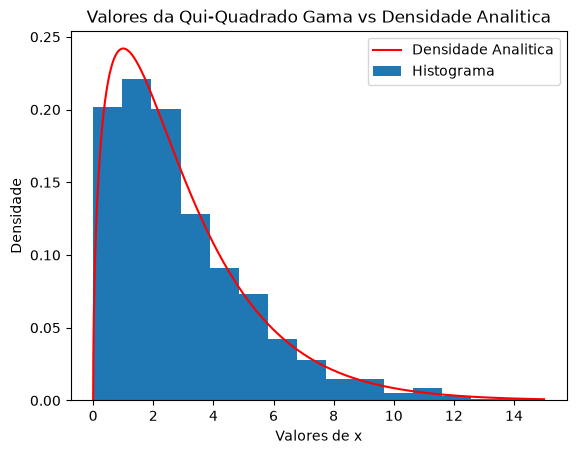

In [236]:
qui_gama = gama(3/2,2, 1000)

eixo_x = np.linspace(0, 15, 10_000)

plt.title("Valores da Qui-Quadrado Gama vs Densidade Analitica")
plt.xlabel('Valores de x')
plt.ylabel('Densidade')

plt.plot(eixo_x, f_qui(eixo_x, 3), color="red", label="Densidade Analitica")
plt.hist(qui_gama, density=True, bins=15, label="Histograma")

plt.legend()
plt.show()

In [233]:
print(f"Valor obtido: {np.mean(qui_gama)}, Valor teorico: 3")
print(f"Valor obtido: {np.var(qui_gama)}, Valor teorico: 6")

Valor obtido: 3.03879881163645, Valor teorico: 3
Valor obtido: 6.0649036086444585, Valor teorico: 6


In [234]:
def qui_quadrado(v, M):
    dados = []
    for i in range(v):
        z = normal(0, 1, M)
        dados.append(np.array(z)**2)

    qui = np.sum(dados, axis=0)

    return qui

# Questão 4. t de Student

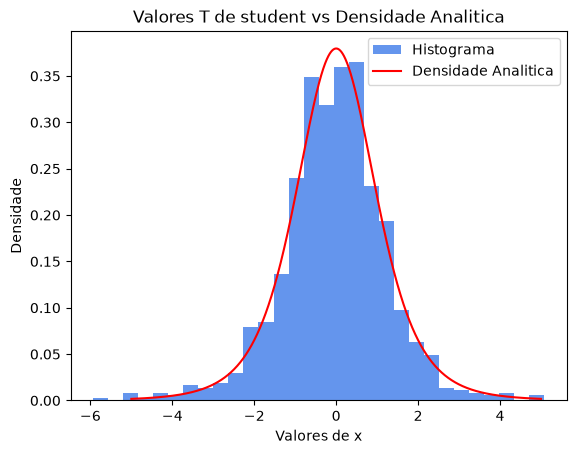

In [248]:
def t_student(v, M):
    qui = qui_quadrado(v, M)
    Z = normal(0, 1, M)

    T = Z/np.sqrt(qui/v)

    return T

def f_tstudent(x, v):
    return math.gamma((v+1)/2)/(math.gamma(v/2) * np.sqrt(v * np.pi) * (1+ (x**2)/v)**((v+1)/2))

eixo_x = np.linspace(-5, 5, 10_000)

t = t_student(5, 1_000)

plt.title("Valores T de student vs Densidade Analitica")
plt.xlabel('Valores de x')
plt.ylabel('Densidade')

plt.hist(t, density=True, bins=30, color="cornflowerblue", label="Histograma")
plt.plot(eixo_x, f_tstudent(eixo_x, 5), color="red", label="Densidade Analitica")

plt.legend()
plt.show()